# Project 4: Predicting Dengue Cases

## Notebook 1 - Data Cleaning, EDA, and Preprocessing

### Contents:
- [1. Problem Statement](##1.-Problem-Statement)
- [2. Data Import & Cleaning](##2.-Data-Import-&-Cleaning)
- [3. EDA](##3.-EDA)

----

## 1. Problem Statement

### Background
Dengue case is a major focus area for the National Environment Agency (NEA) to tackle as it is a significant public health concern in Singapore. Last year, there were [32,173 dengue cases recorded, which was six times the total number of cases in 2021](https://www.nea.gov.sg/media/news/news/index/nea-launches-national-dengue-prevention-campaign-early-urge-vigilance-avert-dengue-outbreak-2023#:~:text=7%20A%20total%20of%2032%2C173,in%20the%20whole%20of%202021.). The number of dengue cases is expected to remain high or increase in the current year of 2023. Hence, it is useful for NEA to be able to predict on the number of dengue cases as accurately as possible in order to proactively allocate resources, implement preventive measures, and raise public awareness to mitigate the spread of Dengue fever.

### Objective and Scope

The goal of this exercise is to develop a predictive model to forecast dengue cases in Singapore for a time horizon range of 3 months to 1 year that NEA can utilize to plan and allocate resources in a cost-efficient manner.

The type of model that will be developed is a time series forecasting model. Success will be evaluated based on the Mean Absolute Percentage Error (MAPE) of the model with a target of 0.10 or less.

The data to be utilized includes Dengue cases between 2014 and 2022 taken from [data.gov.sg](https://data.gov.sg/dataset/weekly-number-of-dengue-and-dengue-haemorrhagic-fever-cases) and [Weekly Infectious Bulletins](https://www.moh.gov.sg/resources-statistics) available at Singapore's Ministry of Health website. External variables such as [weather information](https://open-meteo.com/en/docs/historical-weather-api), and [Google search interest](https://trends.google.com/trends/explore?date=2014-01-01%202022-12-31&geo=SG&q=%2Fm%2F09wsg) will be explored to determine the feasibility of leveraging them as predictors to forecast Dengue cases.

Lastly, the best performing model will be used as a basis for the cost-benefit analysis to derive the potential savings or other benefits that NEA can expect to achieve.


----

## 2. Data Import & Cleaning

### Library Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import datetime as dt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller  
import pmdarima as pm
from pmdarima.arima import ADFTest # to perform ADF test 
pd.set_option('display.float_format', lambda x: '%.3f' % x)

%matplotlib inline

import warnings
warnings.simplefilter(action="ignore")

### Data Import

In [2]:
# Main Dataframe:
dengue_cases = pd.read_csv('../assets/weekly-dengue-2014-2022.csv')

# For trend exploration:

weather = pd.read_csv('../assets/weather 2014-2022.csv')

google_trends = pd.read_csv('../assets/google-search-trend.csv')

### Data Summary

In [3]:
# Overview of the data:
def data_summary(df):
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(f'Shape(row,col): {df.shape}')
    print(f'Number of duplicates: {df.duplicated().sum()}')
    print('-'*60)
    print('Columns containing missing values:')
    isnull_df = pd.DataFrame(df.isnull().sum()).reset_index()
    isnull_df.columns = ['col','num_nulls']
    isnull_df['null_pct'] = (isnull_df['num_nulls']/len(df)).round(2)
    df_nullcheck = isnull_df[isnull_df['num_nulls']>0]
    if len(df_nullcheck) == 0:
       print('None')
    else:
       print(df_nullcheck)
    print('-'*60)
    print(f'Number of unique values in each column and data types:')
    dtypes_df = pd.DataFrame(df.dtypes, columns=['Data Type'])
    unique_counts_df = pd.DataFrame(df.nunique(), columns=['Unique Values'])
    summary_df = pd.concat([dtypes_df, unique_counts_df], axis=1).reset_index()
    print(summary_df)

data_summary(dengue_cases)

Shape(row,col): (954, 4)
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
      col  num_nulls  null_pct
3  number         14     0.010
------------------------------------------------------------
Number of unique values in each column and data types:
         index Data Type  Unique Values
0         year     int64              9
1        eweek     int64             53
2  type_dengue    object              2
3       number   float64            314


In [4]:
# Overview of descriptive statistics:
dengue_cases.describe()

,year,eweek,number
count,954.000,954.000,940.000
mean,2018.000,27.000,146.286
std,2.583,15.305,264.118
min,2014.000,1.000,0.000
25%,2016.000,14.000,0.000
50%,2018.000,27.000,16.000
75%,2020.000,40.000,209.250
max,2022.000,53.000,1791.000


In [5]:
dengue_cases.head()

,year,eweek,type_dengue,number
0,2014,1,Dengue,436.000
1,2014,1,DHF,1.000
2,2014,2,Dengue,479.000
3,2014,2,DHF,0.000
4,2014,3,Dengue,401.000


**Comments:**  
* There are a total of **4 features** (columns) and **954 responses** (rows) in the main dengue dataframe that record number of dengue cases per week from Week 1 of year 2014 to Week 53 of 2022.
* There are no duplicate values (columns/rows).
* There is a handful of missing values in the 'number' column (i.e., number of cases), likely due to missing values in the extra week (Week 53) in most years. Further exploration to be done to confirm this and determine how best to handle it.
* The number of dengue cases in a week ranges from 0 to 1791, with an average of 40.5 cases per week and median of 16 cases per week.
* Some modification has to be done on the date related columns to ensure that they are in the correct format for timeseries analysis further down.

### Data Summary of Potential Exogenous Variables

In [6]:
data_summary(weather)

Shape(row,col): (3287, 5)
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
None
------------------------------------------------------------
Number of unique values in each column and data types:
                      index Data Type  Unique Values
0                      time    object           3287
1   temperature_2m_max (°C)   float64             74
2   temperature_2m_min (°C)   float64             54
3  temperature_2m_mean (°C)   float64             51
4             rain_sum (mm)   float64            315


In [7]:
data_summary(google_trends)

Shape(row,col): (108, 2)
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
None
------------------------------------------------------------
Number of unique values in each column and data types:
                       index Data Type  Unique Values
0                      Month    object            108
1  Dengue fever: (Singapore)     int64             43


**Comments**

* Data type of date-related column in the two trend dataframes are string objects, need to convert to datetime if we are including these in timeseries analysis.

### Data Cleaning

#### Column with Missing Values

In [8]:
# Examine rows with missing values in 'number' column:
dengue_cases[dengue_cases['number'].isnull()]

,year,eweek,type_dengue,number
210,2015,53,Dengue,NaN
211,2015,53,DHF,NaN
316,2016,53,Dengue,NaN
317,2016,53,DHF,NaN
422,2017,53,Dengue,NaN
423,2017,53,DHF,NaN
528,2018,53,Dengue,NaN
529,2018,53,DHF,NaN
634,2019,53,Dengue,NaN
635,2019,53,DHF,NaN


**Comments**

* If the year [starts on a Thursday or is a leap year and starts on a Wednesday, then it has 53 weeks](https://www.timeanddate.com/date/week-numbers.html#:~:text=Most%20years%20have%2052%20weeks,will%20have%2053%20numbered%20weeks). That only happened in 2014 and 2020, leaving missing values in week 53 in the rest of the years in the dataset.
* Since these weeks do not exist, we will drop them from the dataset.

In [9]:
# Drop rows with missing values
dengue_cases.dropna(inplace=True)

# Check if there are any missing values left:
dengue_cases.isnull().sum()

year           0
eweek          0
type_dengue    0
number         0
dtype: int64

#### Dengue Type Definitions

According to United States' Centers for [Disease Control and Prevention (CDC)](https://www.cdc.gov/dengue/resources/denguedhf-information-for-health-care-practitioners_2009.pdf), "some patients with dengue fever go on to develop dengue hemorrhagic fever (DHF)", which is a more severe and sometimes fatal form of dengue fever. 

The weekly dengue cases dataset used in this analysis is taken from:
* Data from 2014 to 2018: [data.gov.sg](https://data.gov.sg/dataset/weekly-number-of-dengue-and-dengue-haemorrhagic-fever-cases), provided by Singapore's Ministry of Health (MOH)
  
* Data from 2019 to 2022: [Weekly Infectious Diseases Bulletin](https://www.moh.gov.sg/resources-statistics) from MOH website

The 'Dengue' and 'DHF' cases in the dataset are reported separately under the 'type_dengue' column in the dataset. However, the definition of 'Dengue' and 'DHF' cases are not clear in the metadata provided together with the dataset from data.gov.sg or MOH website.

Hence, we shall explore and determine if 'Dengue' cases are the sum of both dengue fever and DHF cases or not.


In [10]:
# Display rows where year = 2018 and eweek = 1 to 13:
dengue_cases[(dengue_cases['year']==2018) & (dengue_cases['eweek']<=13)]

,year,eweek,type_dengue,number
424,2018,1,Dengue,83.000
425,2018,1,DHF,0.000
426,2018,2,Dengue,68.000
427,2018,2,DHF,0.000
428,2018,3,Dengue,54.000
429,2018,3,DHF,0.000
430,2018,4,Dengue,45.000
431,2018,4,DHF,0.000
432,2018,5,Dengue,48.000
433,2018,5,DHF,0.000


In [11]:
# Total number of cases in Q1 2018 (eweek 1 to 13) in the dataset:
dengue_cases[(dengue_cases['year']==2018) & (dengue_cases['eweek']<=13)]['number'].sum()

602.0


According to the Q1 2018 dengue surveillance data on [NEA website](https://www.nea.gov.sg/docs/default-source/default-document-library/q1-2018-dengue-surveillance-data-(272kb).pdfa), the number of dengue cases reported is:

<img src="../images/2018q1nea.png" style="width: 50%; height: auto;">

In [12]:
# Number of 'DHF' cases in Q1 2018 (eweek 1 to 13) in the dataset:
dengue_cases[(dengue_cases['year']==2018) & (dengue_cases['eweek']<=13) & (dengue_cases['type_dengue']=='DHF')]['number'].sum()

3.0

**Comments**

* The number of 'Dengue' cases in the dataset is the sum of 'Dengue Fever' and 'DHF' cases. Hence, we will only use the 'Dengue' column for our timeseries analysis to avoid double counting.

In [13]:
# Drop rows where type_dengue = DHF
dengue_cases = dengue_cases.drop(dengue_cases[(dengue_cases['type_dengue']=='DHF')].index)

In [14]:
# reset index
dengue_cases.reset_index(drop=True, inplace=True)

In [15]:
dengue_cases

,year,eweek,type_dengue,number
0,2014,1,Dengue,436.000
1,2014,2,Dengue,479.000
2,2014,3,Dengue,401.000
3,2014,4,Dengue,336.000
4,2014,5,Dengue,234.000
...,...,...,...,...
465,2022,48,Dengue,242.000
466,2022,49,Dengue,326.000
467,2022,50,Dengue,289.000
468,2022,51,Dengue,272.000


#### Datetime Format

'eweek' (Epidemological week) is defined as ['from Sun 0000hrs to Sat 2359hrs'](https://www.nea.gov.sg/dengue-zika/dengue/dengue-cases) according to NEA. Hence, we will use the Sunday date as the first day of the week to format the date column.

In [16]:
# Define the first and last start dates for the range of dates
start_date = pd.to_datetime('2013-12-29')
end_date = pd.to_datetime('2022-12-25')

# Create a new dataframe with the range of weeks from start_date to end_date
date_range = pd.date_range(start_date, end_date, freq='W')
date_range_df = pd.DataFrame(date_range, columns=['date'])

date_range_df.head()


,date
0,2013-12-29
1,2014-01-05
2,2014-01-12
3,2014-01-19
4,2014-01-26


In [17]:
# Concatenate the original_df and date_range_df column-wise
dengue_cases = pd.concat([dengue_cases, date_range_df], axis=1)

dengue_cases

,year,eweek,type_dengue,number,date
0,2014,1,Dengue,436.000,2013-12-29
1,2014,2,Dengue,479.000,2014-01-05
2,2014,3,Dengue,401.000,2014-01-12
3,2014,4,Dengue,336.000,2014-01-19
4,2014,5,Dengue,234.000,2014-01-26
...,...,...,...,...,...
465,2022,48,Dengue,242.000,2022-11-27
466,2022,49,Dengue,326.000,2022-12-04
467,2022,50,Dengue,289.000,2022-12-11
468,2022,51,Dengue,272.000,2022-12-18


In [18]:
dengue_df = dengue_cases.copy()

# Set the date column as the index
dengue_df.set_index('date', inplace=True)

In [19]:
dengue_df.sort_index(inplace=True)

In [20]:
dengue_df

,year,eweek,type_dengue,number
date,,,,
2013-12-29,2014,1,Dengue,436.000
2014-01-05,2014,2,Dengue,479.000
2014-01-12,2014,3,Dengue,401.000
2014-01-19,2014,4,Dengue,336.000
2014-01-26,2014,5,Dengue,234.000
...,...,...,...,...
2022-11-27,2022,48,Dengue,242.000
2022-12-04,2022,49,Dengue,326.000
2022-12-11,2022,50,Dengue,289.000


In [21]:
# convert the 'time' column in 'weather' dataframe to datetime format
weather['time'] = pd.to_datetime(weather['time'], format='%d/%m/%y')

weather.head()

,time,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),rain_sum (mm)
0,2014-01-01,27.600,24.300,25.600,0.500
1,2014-01-02,28.000,24.300,25.800,0.500
2,2014-01-03,27.800,24.500,25.700,1.700
3,2014-01-04,28.300,24.200,25.800,2.900
4,2014-01-05,26.400,23.800,24.700,7.900


In [22]:
weather_df = weather.copy()

# Set the time column as the index
weather_df.set_index('time', inplace=True)
weather_df.sort_index(inplace=True)

In [23]:
# convert the 'time' column in 'google_trends' dataframe to datetime format
google_trends['Month'] = pd.to_datetime(google_trends['Month'], format='%Y-%m')

google_trends.head()

,Month,Dengue fever: (Singapore)
0,2014-01-01,34
1,2014-02-01,31
2,2014-03-01,26
3,2014-04-01,27
4,2014-05-01,26


In [24]:
google_df = google_trends.copy()

google_df.set_index('Month', inplace=True)
google_df.sort_index(inplace=True)

## 3. EDA

### EDA on Dengue Cases Data

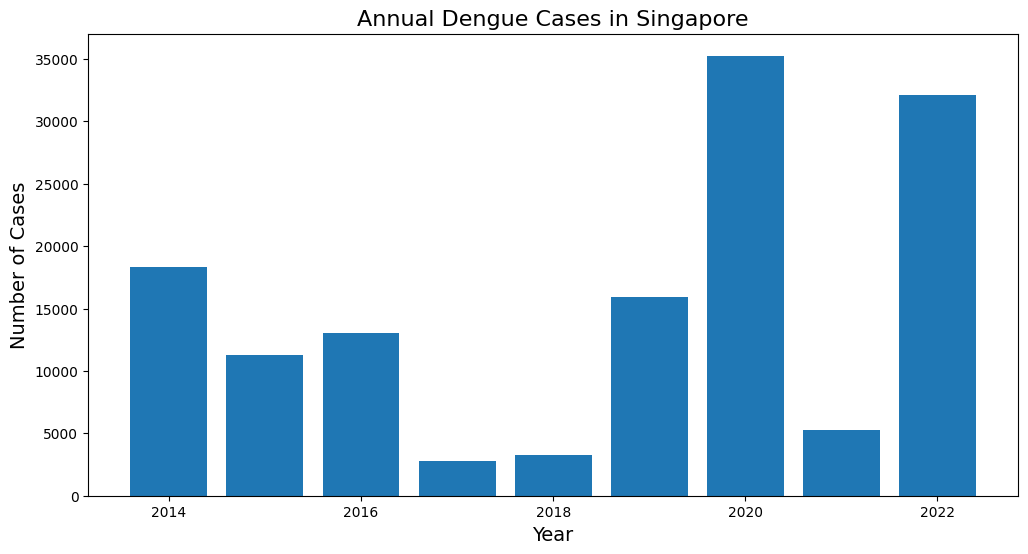

In [25]:
# Group the data by year and calculate the sum of values
annual_cases = dengue_df.groupby('year')['number'].sum()

# Plot the annual_cases as a bar chart
plt.figure(figsize=(12,6))
plt.bar(annual_cases.index, annual_cases)

plt.title('Annual Dengue Cases in Singapore', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Number of Cases', fontsize=14)

plt.show()

**Comments**

* Between 2014 and 2022, the lowest number of dengue casese was recorded in 2017 (2,772 dengue cases), [which was the lowest figure in the last 16 years](https://www.straitstimes.com/singapore/2772-dengue-cases-in-2017-the-lowest-in-the-last-16-years-nea) due to few reasons:

  * The Singapore population has built up immunity after a high number of cases in the last few years where there were dengue outbreaks.
  * Concerted effort by the community and NEA in response to the Zika outbreak in the second half of 2016.
  * Relatively large network of about 50,000 Gravitraps (traps that catch Aedes aegypti mosquitoes and collect data on them) deployed to actively monitor mosquito population which allowed NEA to take preventive measures early.

   
* The highest number of weekly cases took place in 2020 (35,315). This is likely due to the Covid-19 pandemic, which resulted in more people staying at home and thus [more conducive for the transmission of Dengue due to the following reasons](https://www.channelnewsasia.com/commentary/why-singapore-record-high-dengue-cases-covid-19-2020-coronavirus-687281): 
 
  * Increased likelihood of mosquitoes acquiring the infection from dengue-infected individuals, and then passing it on when they bite healthy individuals. 
  
  * Mosquito is known to bite during the day, peaking at dawn and dusk, rather than at night, and dwell among human habitats. During the pandemic, more people stayed at home throughout the day, which implied more contact between Aedes mosquitoes and humans.

* The number of cases dipped significantly in the subsequent year 2021 possibly because of most resources being [focused on handling COVID-19 pandemic](https://www.channelnewsasia.com/asia/dengue-fever-plummet-southeast-asia-2021-covid-19-lockdown-1949581) hence resulting in reduced priority in dengue monitoring, under-detection & under-reporting of cases due to higher reluctance to seek medical care at healthcare facilities and reduced access to health facilities, etc.

* The number of cases [soared again in the following year 2022](https://www.straitstimes.com/singapore/health/number-of-dengue-cases-in-2022-likely-to-be-second-highest-on-record) to 32,173, which can be attributed to:
  * Lower immunity against the DenV-3 strain of the dengue virus, which made up majority of the cases.
  
  * Increased construction work leading to more breeding sites for mosquitoes.
  
  * Warmer climate conditions which shortened the incubation cycle of Aedes mosquitoes.

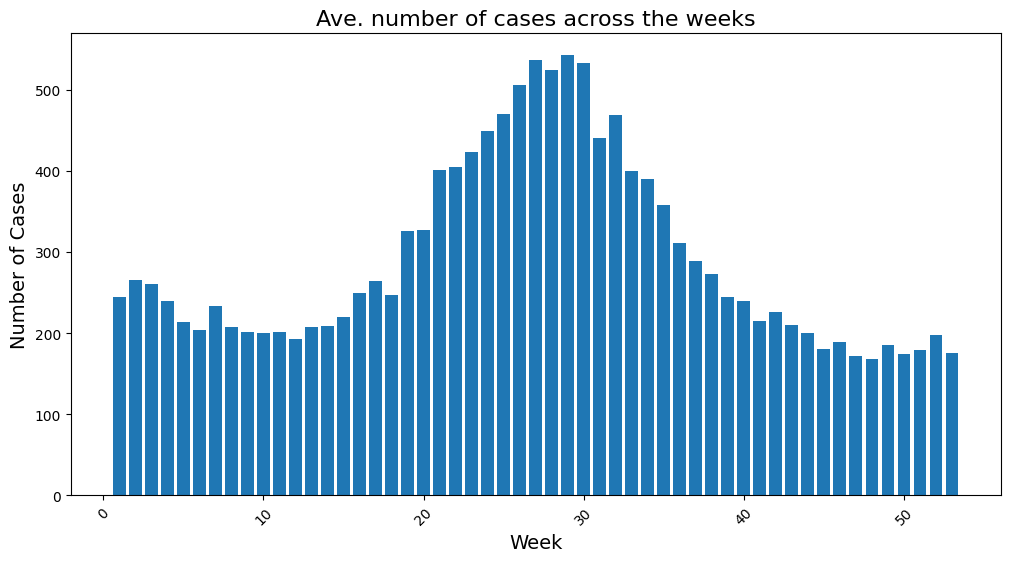

In [26]:
# Cases across weeks over the year
weekly_cases = dengue_df.groupby('eweek')['number'].mean()

# Plot the weekly_cases as a bar chart
plt.figure(figsize=(12,6))
plt.bar (weekly_cases.index, weekly_cases, color='tab:blue')

plt.title('Ave. number of cases across the weeks', fontsize=16)
plt.xlabel('Week', fontsize=14)
plt.xticks (rotation=45)
plt.ylabel('Number of Cases', fontsize=14)

plt.show()

In [27]:
# Create new dataframe with only the 'number' column
weekly_dengue = dengue_df[['number']].copy()

# Verify the result
print(f'Shape(row,col): {weekly_dengue.shape}')
print(f'Range of dates: {weekly_dengue.index.min()} to {weekly_dengue.index.max()}')
weekly_dengue.head()

Shape(row,col): (470, 1)
Range of dates: 2013-12-29 00:00:00 to 2022-12-25 00:00:00


,number
date,
2013-12-29,436.000
2014-01-05,479.000
2014-01-12,401.000
2014-01-19,336.000
2014-01-26,234.000


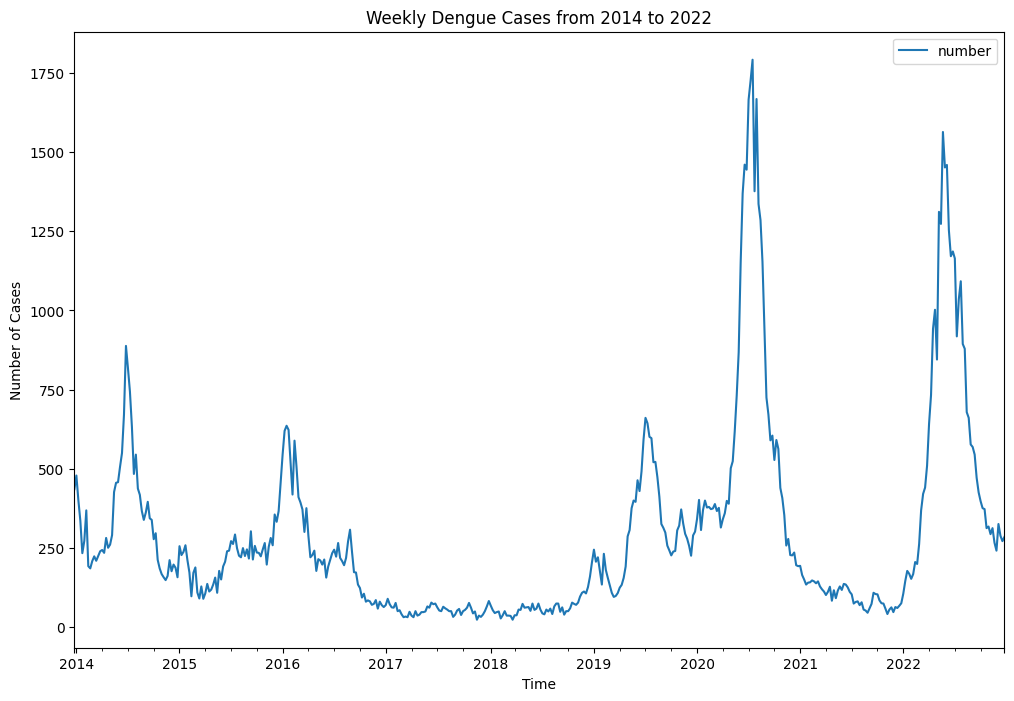

In [28]:
# Plot weekly dengue cases between 2014 and 2022
weekly_dengue.plot(figsize=(12,8))
plt.title('Weekly Dengue Cases from 2014 to 2022')
plt.ylabel('Number of Cases')
plt.xlabel('Time')
plt.show()

**Comments**
* The peak of Dengue cases seem to occur more often in the middle of the year (June/July) possibly due to higher temperature during this period, which [facilitate breeding and hatch rates of Aedes mosquitoes and faster replication of the dengue virus](https://www.nea.gov.sg/media/news/news/index/nea-urges-continued-vigilance-as-aedes-aegypti-mosquito-population-and-number-of-dengue-cases-remain-high-at-the-start-of-2020).
  
* However, the peak season appeared to be rather erratic across the years. For example, in 2014, the peak season occurred in June/July, while in 2015, the peak season appeared to begin around 3rd quarter of the year. Then in 2016, the peak took place in first quarter of the year, followed by a smaller peak in the middle of that year.

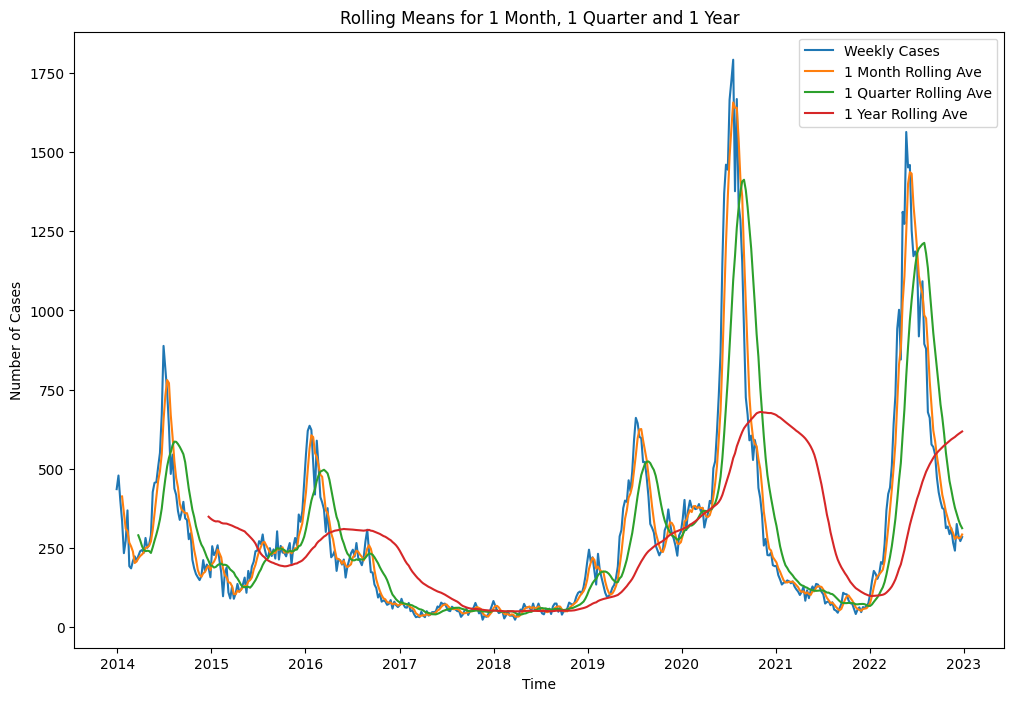

In [29]:
# Plot Rolling means for 1 month, 1 quarter and 1 year
plt.figure(figsize=(12,8))
plt.plot(weekly_dengue['number'], label='Weekly Cases')
plt.plot(weekly_dengue['number'].rolling(4).mean(), label='1 Month Rolling Ave')
plt.plot(weekly_dengue['number'].rolling(13).mean(), label='1 Quarter Rolling Ave')
plt.plot(weekly_dengue['number'].rolling(52).mean(), label='1 Year Rolling Ave')

plt.legend(loc='best')
plt.title('Rolling Means for 1 Month, 1 Quarter and 1 Year')
plt.ylabel('Number of Cases')
plt.xlabel('Time')

plt.show();

**Comments**

* Similar to weekly cases line plot, there is no apparent regular seasonal pattern observed from rolling averages. 

### EDA on Exogenous Variables

#### Rainfall Data

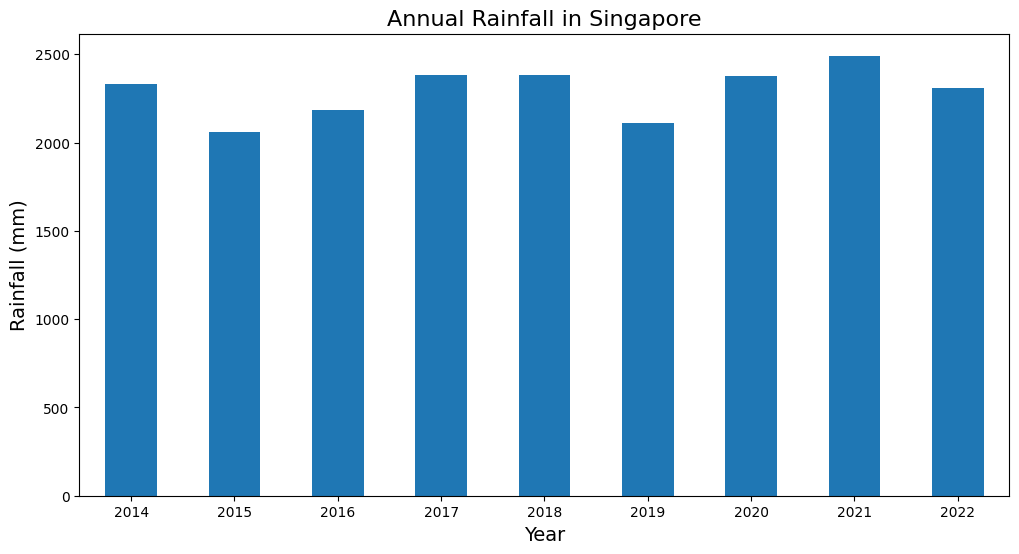

In [30]:
# Sum rainfall by year
annual_rainfall = weather_df.resample('Y')['rain_sum (mm)'].sum()

# Plot the annual_rainfall as a bar chart
plt.figure(figsize=(12,6))
annual_rainfall.plot(kind='bar',color='tab:blue')

plt.title('Annual Rainfall in Singapore', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Rainfall (mm)', fontsize=14)

# Format x-axis labels to show only the year
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(plt.FixedFormatter(annual_rainfall.index.strftime('%Y')))

plt.show()

In [31]:
# Aggregate daily rainfall to weekly rainfall
weekly_rainfall = weather_df.resample('W')['rain_sum (mm)'].sum().to_frame()

print(f'Shape(row,col): {weekly_rainfall.shape}')
weekly_rainfall.head()

Shape(row,col): (470, 1)


,rain_sum (mm)
time,
2014-01-05,13.500
2014-01-12,31.700
2014-01-19,10.600
2014-01-26,4.700
2014-02-02,3.000


In [32]:
# replace weekly_rainfall index with weekly_dengue index
weekly_rainfall.index = weekly_dengue.index

weekly_rainfall.head(12)

,rain_sum (mm)
date,
2013-12-29,13.500
2014-01-05,31.700
2014-01-12,10.600
2014-01-19,4.700
2014-01-26,3.000
2014-02-02,2.500
2014-02-09,8.600
2014-02-16,1.100
2014-02-23,0.000


In [33]:
# concatenate the 'eweek' column from dengue_cases to weekly_rainfall
weekly_rainfall = pd.concat([weekly_rainfall, dengue_df['eweek']], axis=1)

In [34]:
weekly_rainfall

,rain_sum (mm),eweek
date,,
2013-12-29,13.500,1
2014-01-05,31.700,2
2014-01-12,10.600,3
2014-01-19,4.700,4
2014-01-26,3.000,5
...,...,...
2022-11-27,69.100,48
2022-12-04,57.100,49
2022-12-11,60.500,50


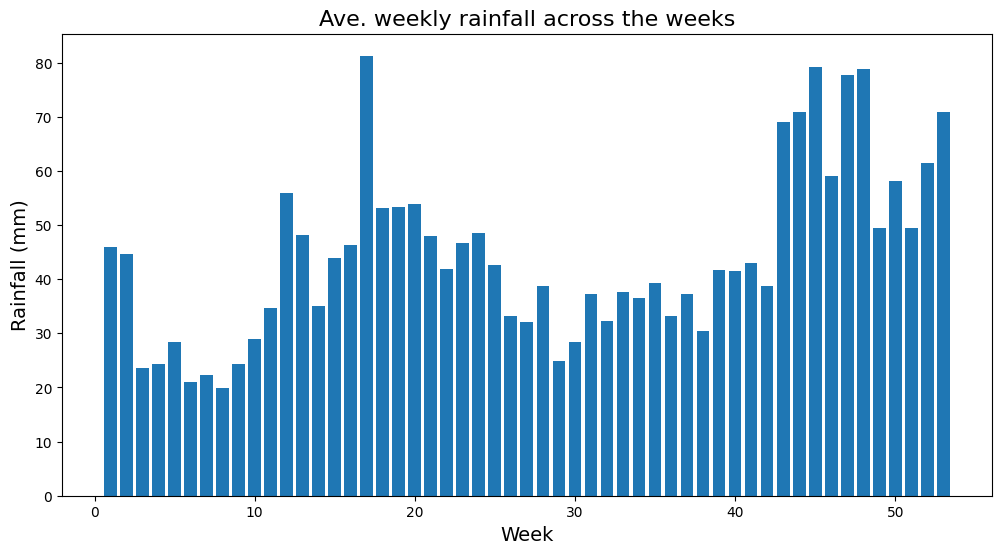

In [35]:
# average weekly rainfall across the weeks over the years
ave_weekly_rainfall = weekly_rainfall.groupby('eweek')['rain_sum (mm)'].mean()

# Plot the average weekly rainfall as a bar chart
plt.figure(figsize=(12,6))
plt.bar (ave_weekly_rainfall.index, ave_weekly_rainfall, color='tab:blue')

plt.title('Ave. weekly rainfall across the weeks', fontsize=16)
plt.xlabel('Week', fontsize=14)
plt.xticks (rotation=0)
plt.ylabel('Rainfall (mm)', fontsize=14)

plt.show()

**Comments**

* In general, there is more rainfall towards the end of the year (October to December) and less rainfall in the middle of the year (June to August).
* This trend seemed to contradict with the understanding that more rainfall would lead to more mosquito breeding and hence more dengue cases. On the other hand, it is also understood that warmer temperature would lead to more mosquito breeding and hence more dengue cases. Hence, we shall explore the relationship between dengue and temperature + rainfall further down.

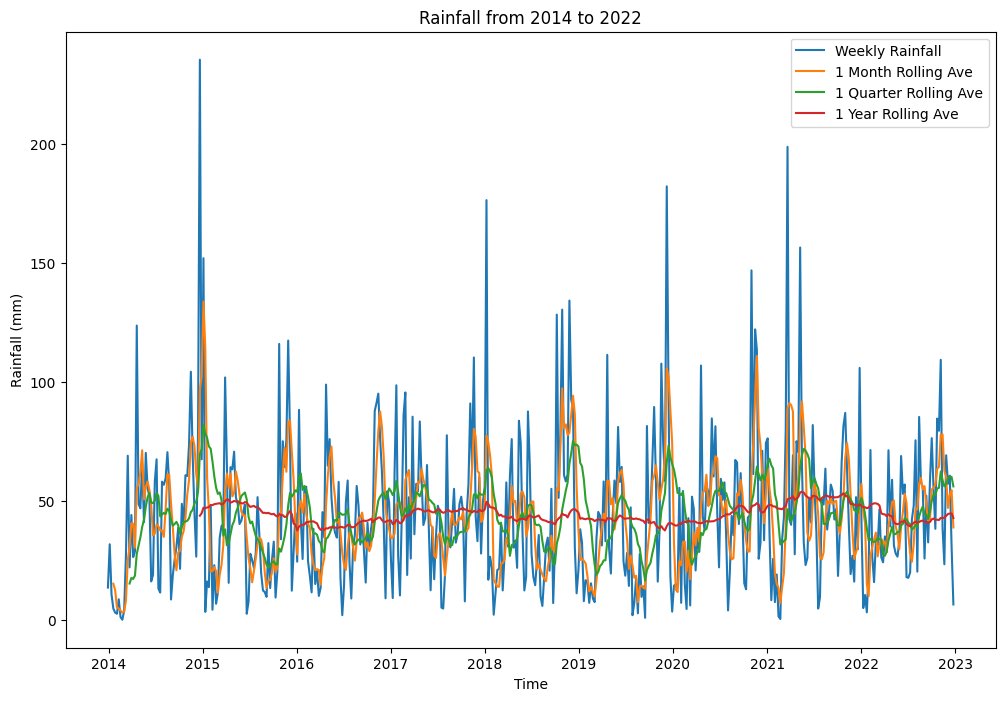

In [36]:
# Weekly rainfall between 2014 and 2022
plt.figure(figsize=(12,8))
plt.plot(weekly_rainfall['rain_sum (mm)'], label='Weekly Rainfall')
plt.plot(weekly_rainfall['rain_sum (mm)'].rolling(4).mean(), label='1 Month Rolling Ave')
plt.plot(weekly_rainfall['rain_sum (mm)'].rolling(13).mean(), label='1 Quarter Rolling Ave')
plt.plot(weekly_rainfall['rain_sum (mm)'].rolling(52).mean(), label='1 Year Rolling Ave')

plt.title('Rainfall from 2014 to 2022')
plt.legend(loc='best')
plt.ylabel('Rainfall (mm)')
plt.xlabel('Time')
plt.show()

**Comments**

* Based on visual comparison of the graphs of dengue cases and rainfall across different time intervals, the amount of rainfall does not seem to be highly correlated with the number of dengue cases. However, we will still perform correlation analysis to confirm this.

#### Google Search Trend Data

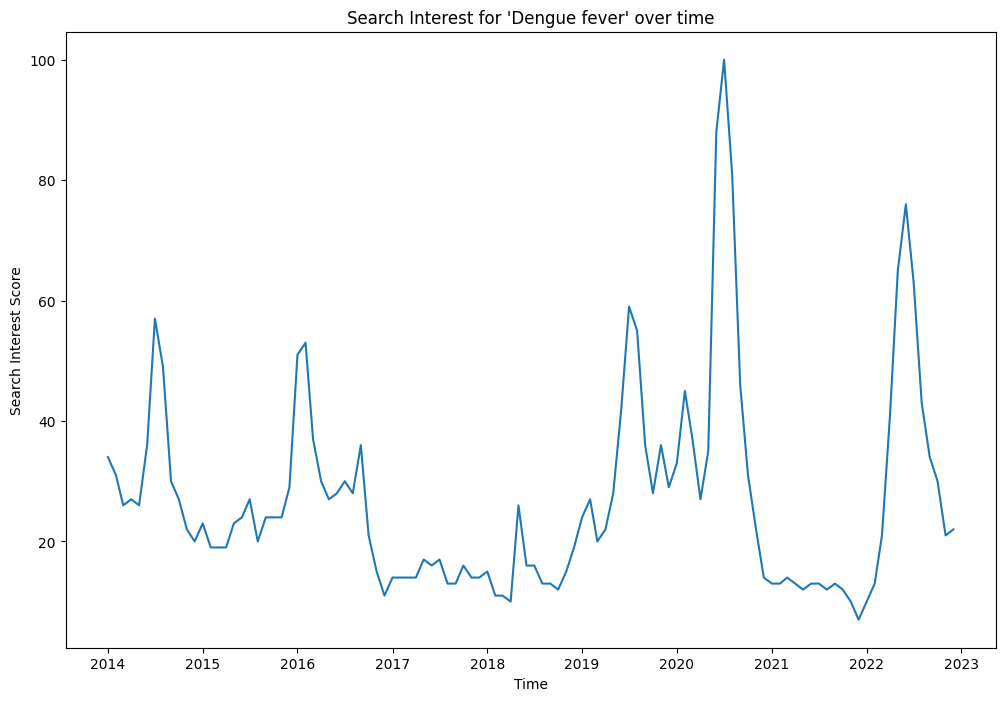

In [37]:
# Interest over time 
plt.figure(figsize=(12,8))
plt.plot(google_df['Dengue fever: (Singapore)'], label='dengue')

plt.title("Search Interest for 'Dengue fever' over time")
plt.ylabel('Search Interest Score')
plt.xlabel('Time')

plt.show();

**Comments**

* From visual comparison, the trendline for 'dengue' search term seems to be consistent with the trendline for weekly dengue cases. However, we will still perform correlation analysis to confirm this.

#### Correlation between Dengue Cases and Exogenous Variables

* Usually, there is a time lapse between weather pattern and the formation of a mosquito breeding habitat. Hence, we will add a column that shift the rainfall and temperature data back by 1 week to account for this time lapse.
  
* Google search interest is typically known as a "real-time" present indication of interest and logically less so as a predictor of future dengue cases, and also considering the availability of data in different time interval (monthly instead of weekly like the dengue case data), we will analyse the correlation of these two sets of external variables (weather and google search interest) to dengue cases separately.

In [38]:
# Define correlation heatmap function
def corr_heatmap(df, title):
    plt.figure(figsize=(10,6))
    plt.title(title, fontsize=14)
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)

# Get correlation of variables
    corr = df.corr().round(2)

# Generate a mask for the upper triangle to hide unnecesary values
    mask = np.zeros_like(corr)
    mask[np.triu_indices_from(mask)] = True

# Set up color scheme
    cmap = sns.color_palette("vlag", as_cmap=True)

# Plot correlation heatmap with mask
    with sns.axes_style("white"):
        sns.heatmap(corr, mask = mask, square = True, annot = True, vmin = -1, vmax = 1, linewidths = 1, annot_kws={"size":12}, cbar_kws={"shrink":1}, cmap=cmap);

#### Dengue and Weather Correlation

In [39]:
# Aggregate daily temperatures to weekly average temperatures
weekly_max_temp = weather_df.resample('W')['temperature_2m_max (°C)'].mean().to_frame()
weekly_min_temp = weather_df.resample('W')['temperature_2m_min (°C)'].mean().to_frame()
weekly_mean_temp = weather_df.resample('W')['temperature_2m_mean (°C)'].mean().to_frame()

In [40]:
temp_df = pd.concat([weekly_max_temp, weekly_min_temp, weekly_mean_temp], axis=1)

In [41]:
# replace weekly_rainfall index with weekly_dengue index
temp_df.index = weekly_dengue.index

In [42]:
dengue_weather = pd.concat([weekly_dengue, weekly_rainfall, temp_df], axis=1)

In [43]:
print (f'Shape(row,col): {dengue_weather.shape}')
dengue_weather.head()

Shape(row,col): (470, 6)


,number,rain_sum (mm),eweek,temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C)
date,,,,,,
2013-12-29,436.000,13.500,1,27.620,24.220,25.520
2014-01-05,479.000,31.700,2,27.971,23.929,25.500
2014-01-12,401.000,10.600,3,27.400,23.986,25.300
2014-01-19,336.000,4.700,4,27.243,23.314,24.871
2014-01-26,234.000,3.000,5,28.371,22.929,25.086


In [44]:
# drop eweek
dengue_weather = dengue_weather.drop(columns=['eweek'])

In [45]:
# Rename columns
dengue_weather.columns = ['dengue_cases', 'weekly_rainfall', 'max_temp', 'min_temp', 'mean_temp']

In [46]:
# Shift weather data by 1 week
dengue_weather['prev_wk_rainfall'] = dengue_weather['weekly_rainfall'].shift(1)
dengue_weather['prev_wk_max_temp'] = dengue_weather['max_temp'].shift(1)
dengue_weather['prev_wk_min_temp'] = dengue_weather['min_temp'].shift(1)
dengue_weather['prev_wk_mean_temp'] = dengue_weather['mean_temp'].shift(1)

# Drop first row of NaN values
dengue_weather = dengue_weather.dropna()

In [47]:
dengue_weather.head()

,dengue_cases,weekly_rainfall,max_temp,min_temp,mean_temp,prev_wk_rainfall,prev_wk_max_temp,prev_wk_min_temp,prev_wk_mean_temp
date,,,,,,,,,
2014-01-05,479.000,31.700,27.971,23.929,25.500,13.500,27.620,24.220,25.520
2014-01-12,401.000,10.600,27.400,23.986,25.300,31.700,27.971,23.929,25.500
2014-01-19,336.000,4.700,27.243,23.314,24.871,10.600,27.400,23.986,25.300
2014-01-26,234.000,3.000,28.371,22.929,25.086,4.700,27.243,23.314,24.871
2014-02-02,273.000,2.500,29.714,23.514,26.000,3.000,28.371,22.929,25.086


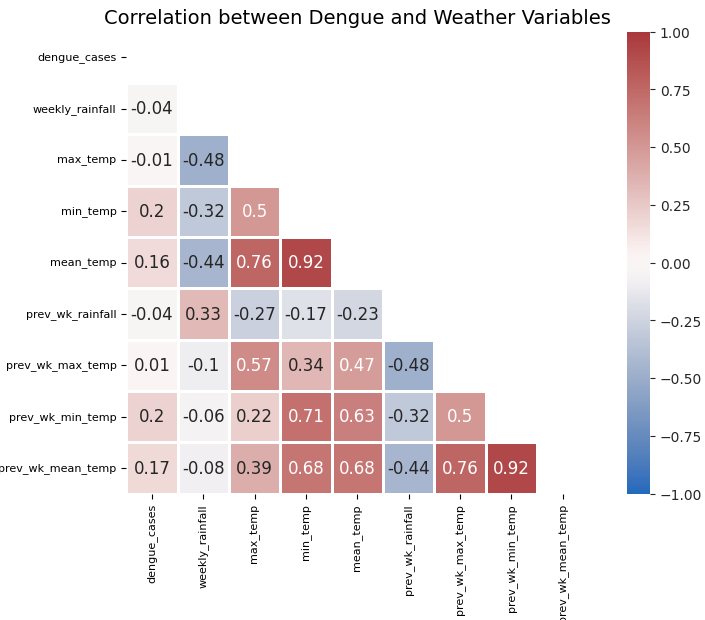

In [48]:
corr_heatmap(dengue_weather, 'Correlation between Dengue and Weather Variables')

**Comments**

* No strong correlation between dengue and weather variables was observed, although temperatures were slightly more correlated with dengue cases, which was in line with the understanding that higher temperatures might contribute to higher dengue cases.
* It can be concluded that weather variables are not good predictors of dengue cases and thus will be excluded from timeseries modelling.

#### Dengue and Google Search Interest Correlation

In [49]:
# Recap google search interest data
print(google_df.shape)
google_df.head()

(108, 1)


,Dengue fever: (Singapore)
Month,
2014-01-01,34
2014-02-01,31
2014-03-01,26
2014-04-01,27
2014-05-01,26


**Comments**

* As the google search interest data is only in monthly interval, we will aggregate weekly dengue cases data by month for consistency before performing correlation analysis.

In [50]:
# Aggregate weekly cases by month
monthly_dengue = weekly_dengue.resample('M')['number'].sum().to_frame()

# group first two rows together due to mismatch in dates when converted to month
monthly_dengue.iloc[1] = monthly_dengue.iloc[0] + monthly_dengue.iloc[1]

# drop first row
monthly_dengue.drop(monthly_dengue.index[0], inplace=True)

print (f'Shape(row,col): {monthly_dengue.shape}')
monthly_dengue.head(12)

Shape(row,col): (108, 1)


,number
date,
2014-01-31,1886.000
2014-02-28,1021.000
2014-03-31,1108.000
2014-04-30,1012.000
2014-05-31,1435.000
2014-06-30,3073.000
2014-07-31,2679.000
2014-08-31,2107.000
2014-09-30,1441.000


In [51]:
# Change datetime format to match monthly_dengue where the index is the last day of the month
google_df.index = google_df.index + pd.DateOffset(months=1) - pd.DateOffset(days=1)

google_df.head()

,Dengue fever: (Singapore)
Month,
2014-01-31,34
2014-02-28,31
2014-03-31,26
2014-04-30,27
2014-05-31,26


In [52]:
# combine all dataframes together
dengue_google = pd.concat([monthly_dengue, google_df], axis=1)

print (f'Shape(row,col): {dengue_google.shape}')
dengue_google.head(12)

Shape(row,col): (108, 2)


,number,Dengue fever: (Singapore)
2014-01-31,1886.000,34
2014-02-28,1021.000,31
2014-03-31,1108.000,26
2014-04-30,1012.000,27
2014-05-31,1435.000,26
2014-06-30,3073.000,36
2014-07-31,2679.000,57
2014-08-31,2107.000,49
2014-09-30,1441.000,30
2014-10-31,974.000,27


In [53]:
# Rename columns
dengue_google.columns = ['dengue_cases', 'search_interest']

**The Impact of Time Lag between Google Search Interest and Dengue Cases on Future Dengue Prediction**

* Normally, Google search interest is more like an indicator of current interest. Nonetheless, we shall investigate if there is any strong correlation between previous month's google search interest and current month's dengue cases

In [54]:
# Shift search interest data by 1 week to see if there is any correlation to future dengue cases
dengue_google['prev_mth_search'] = dengue_google['search_interest'].shift(1)

# Drop first row of NaN values
dengue_google = dengue_google.dropna()

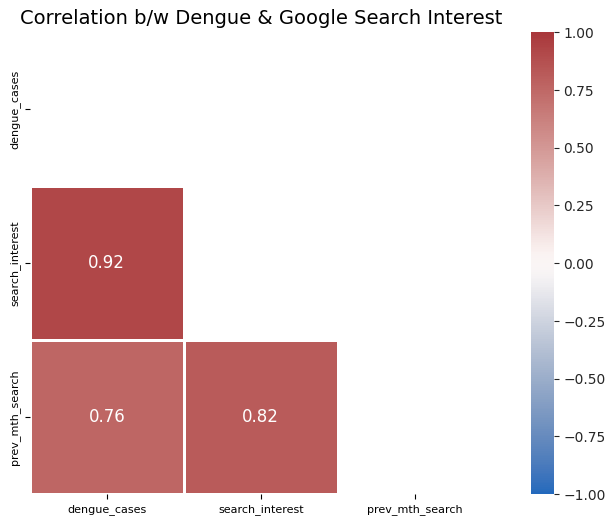

In [55]:
corr_heatmap(dengue_google, 'Correlation b/w Dengue & Google Search Interest')

**Comments**

* In line with earlier inference, the 'dengue' search term and number of dengue cases are strongly correlated at 0.92. Interestingly, the correlation of previous month's search interest for 'dengue' to dengue cases is also relatively high at 0.76. 
* We will determine later if it is beneficial to include previous month's google search interest as a predictor in our timeseries model.

### Autocorrelations of Dengue Cases

In [56]:
print(f'Autocorrelation between weekly dengue cases and 1-week lag: {round(dengue_df["number"].autocorr(lag=1),4)}')
print(f'Autocorrelation between weekly dengue cases and 1-month lag: {round(dengue_df["number"].autocorr(lag=4),4)}')
print(f'Autocorrelation between weekly dengue cases and 1-quarter lag: {round(dengue_df["number"].autocorr(lag=13),4)}')
print(f'Autocorrelation between weekly dengue cases and 1-year lag: {round(dengue_df["number"].autocorr(lag=52),4)}')

Autocorrelation between weekly dengue cases and 1-week lag: 0.9769
Autocorrelation between weekly dengue cases and 1-month lag: 0.8753
Autocorrelation between weekly dengue cases and 1-quarter lag: 0.3804
Autocorrelation between weekly dengue cases and 1-year lag: -0.0218


**Comments**

* The correlation between number of cases in each week and 1 week ago is the strongest at 0.975. As the lag increases, the correlation decreases. There coule be a few possible reasons to explain this pattern:
  
  * The [typical lifecycle of an Aedes mosquito](https://www.nea.gov.sg/dengue-zika/prevent-aedes-mosquito-breeding/aedes-mosquito) from an an egg to adult mosquito is about 7 days and 3 days after the mosquito has bitten a person and taken in blood, it will lay eggs, and the cycle repeats. The average lifespan of an Aedes mosquito in nature is two weeks. Hence, if a mosquito has infected a person with dengue fever in a week, it can still bite and infect other people in the following week provided that it is still alive.
  
  * There is a time lapse between identification of a cluster and implementing actions to curb the spread of Dengue. One week might be too short a time period for NEA to identify dengue cluster and/or detect mosquito breeding habitats. As time passes, the probability of NEA taken actions to curb the spread increases.

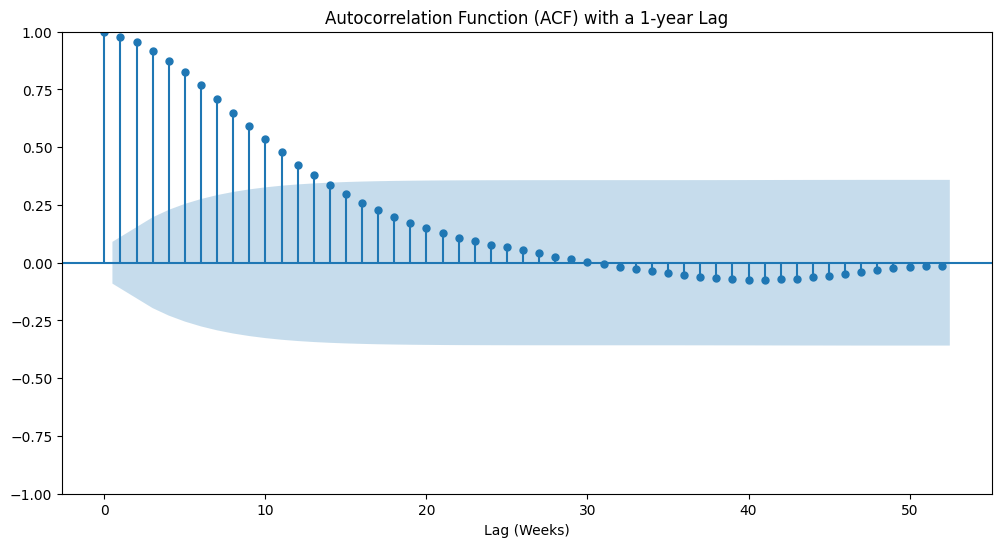

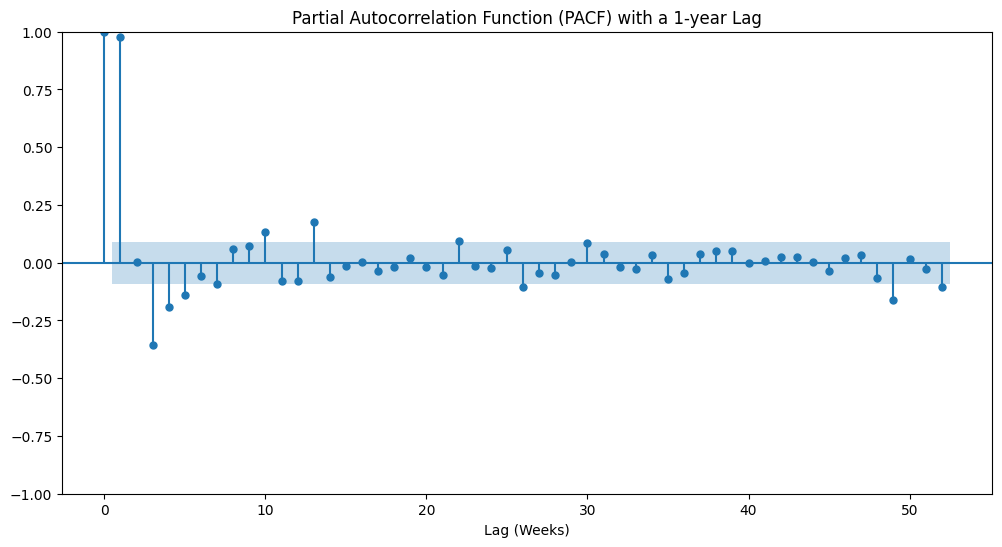

In [57]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_acf(dengue_df["number"], lags=52, ax=ax)
plt.title("Autocorrelation Function (ACF) with a 1-year Lag")
plt.xlabel("Lag (Weeks)")

fig, ax = plt.subplots(figsize=(12, 6))
plot_pacf(dengue_df["number"], lags=52, ax=ax)
plt.title("Partial Autocorrelation Function (PACF) with a 1-year Lag")
plt.xlabel("Lag (Weeks)")
plt.show()

**Comments**

* There are several autocorrelations that are significantly non-zero. Therefore, the time series is non-random.

* **ACF** - The ACF plot captures the correlation between Lag 0 of a time series and all immediate subsequent lags after that. This plot shows the strongest positive correlation at lag 1, followed by a gradual decline in correlation as the lag increases. After Lag 13, the correlation is not significant as the confidence interval crosses the 0 line. However, this pattern is not repeated every 13 lags, which suggests that there is no regular seasonality pattern.
  
* **PACF** - The PACF plot captures a “direct” correlation between Lag 0 of a time series and that particular Lag "t-(x)" version of itself. The PACF plot above shows a strong positive correlation at Lag 1. The remaining lags show that strong a correlation to Lag 0 of the time series with Lag 13 being the last spike out of the confidence interval.

### Export Datasets for Modelling

In [58]:
# Export the datasets to CSV files:

weekly_dengue.to_csv('../data/weekly_dengue.csv', index=True)

dengue_google.to_csv('../data/dengue_google.csv', index=True)